# EN3160 Assignment 03

230197M Garusinghe SB

## Question 1

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cpu


In [ ]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size_cifar = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=cifar_transform
)
testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=cifar_transform
)

trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size_cifar, shuffle=True, num_workers=2
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size_cifar, shuffle=False, num_workers=2
)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

print("Training images:", len(trainset))
print("Test images:", len(testset))

100.0%


Training images: 50000
Test images: 10000


### 1(a)

In [ ]:
Din = 3 * 32 * 32
H = 100
K = 10

# Xavier initialization
W1 = torch.randn(Din, H, device=device) * (2 / (Din + H))**0.5
b1 = torch.zeros(H, device=device)
W2 = torch.randn(H, K, device=device) * (2 / (H + K))**0.5
b2 = torch.zeros(K, device=device)

lr = 0.1
lr_decay = 0.9
epochs_cifar = 10


def forward(x):
    h = torch.sigmoid(x @ W1 + b1)
    logits = h @ W2 + b2
    return h, logits

### 1(b)

In [ ]:
def train_step(inputs, labels, learning_rate):
    global W1, b1, W2, b2

    N = inputs.shape[0]
    x = inputs.reshape(N, -1)

    with torch.no_grad():
        h, logits = forward(x)
        loss = F.cross_entropy(logits, labels)

        # dL/d(logits) for softmax cross-entropy
        probs = torch.softmax(logits, dim=1)
        dlogits = probs.clone()
        dlogits[torch.arange(N, device=device), labels] -= 1
        dlogits /= N

        dW2 = h.T @ dlogits
        db2 = dlogits.sum(dim=0)

        dh = dlogits @ W2.T
        dz1 = dh * h * (1 - h)
        dW1 = x.T @ dz1
        db1 = dz1.sum(dim=0)

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    return loss.item()


def evaluate_dense(loader):
    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            x = inputs.reshape(inputs.shape[0], -1)

            _, logits = forward(x)
            loss = F.cross_entropy(logits, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total

### 1(c)

In [ ]:
train_losses = []
test_losses = []
train_accuracies = []
test_accuracies = []

for epoch in range(epochs_cifar):
    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        train_step(inputs, labels, lr)

    train_loss, train_acc = evaluate_dense(trainloader)
    test_loss, test_acc = evaluate_dense(testloader)

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(
        f"Epoch {epoch+1:02d}/{epochs_cifar} | "
        f"Train loss: {train_loss:.4f} | Test loss: {test_loss:.4f} | "
        f"Train acc: {train_acc:.2f}% | Test acc: {test_acc:.2f}%"
    )
    lr *= lr_decay

Epoch 01/10 | Train loss: 1.6927 | Test loss: 1.7078 | Train acc: 41.19% | Test acc: 40.62%
Epoch 02/10 | Train loss: 1.6188 | Test loss: 1.6555 | Train acc: 44.69% | Test acc: 42.66%
Epoch 03/10 | Train loss: 1.5672 | Test loss: 1.6185 | Train acc: 45.78% | Test acc: 44.01%
Epoch 04/10 | Train loss: 1.5218 | Test loss: 1.5867 | Train acc: 47.79% | Test acc: 45.00%
Epoch 05/10 | Train loss: 1.4833 | Test loss: 1.5625 | Train acc: 49.12% | Test acc: 46.40%
Epoch 06/10 | Train loss: 1.4478 | Test loss: 1.5486 | Train acc: 50.74% | Test acc: 46.87%
Epoch 07/10 | Train loss: 1.4171 | Test loss: 1.5261 | Train acc: 51.67% | Test acc: 47.37%
Epoch 08/10 | Train loss: 1.3950 | Test loss: 1.5183 | Train acc: 52.37% | Test acc: 48.13%
Epoch 09/10 | Train loss: 1.3742 | Test loss: 1.5090 | Train acc: 53.30% | Test acc: 48.19%
Epoch 10/10 | Train loss: 1.3565 | Test loss: 1.5016 | Train acc: 53.88% | Test acc: 48.26%


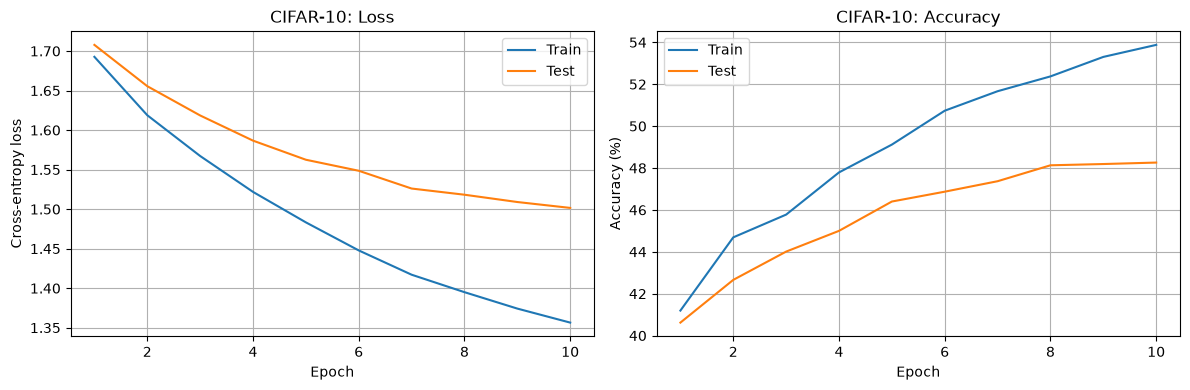

Final training accuracy: 53.88%
Final test accuracy:     48.26%


In [ ]:
epochs_range = range(1, epochs_cifar + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, train_losses, label="Train")
axes[0].plot(epochs_range, test_losses, label="Test")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="CIFAR-10: Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs_range, train_accuracies, label="Train")
axes[1].plot(epochs_range, test_accuracies, label="Test")
axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="CIFAR-10: Accuracy")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

print(f"Final training accuracy: {train_accuracies[-1]:.2f}%")
print(f"Final test accuracy:     {test_accuracies[-1]:.2f}%")

## Question 2

In [ ]:
transform_mnist = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size_mnist = 128

trainset_mnist = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform_mnist
)
testset_mnist = torchvision.datasets.MNIST(
    root="./data", train=False, download=True, transform=transform_mnist
)

trainloader_mnist = torch.utils.data.DataLoader(
    trainset_mnist, batch_size=batch_size_mnist, shuffle=True, num_workers=2
)
testloader_mnist = torch.utils.data.DataLoader(
    testset_mnist, batch_size=batch_size_mnist, shuffle=False, num_workers=2
)

print("Training images:", len(trainset_mnist))
print("Test images:", len(testset_mnist))

100.0%
100.0%
100.0%
100.0%

Training images: 60000
Test images: 10000


### 2(a)

In [ ]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.conv3 = nn.Conv2d(16, 120, kernel_size=5)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.activation = nn.Tanh()
        self.fc1 = nn.Linear(120, 84)
        self.fc2 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(self.activation(self.conv1(x)))
        x = self.pool(self.activation(self.conv2(x)))
        x = self.activation(self.conv3(x))
        x = torch.flatten(x, 1)
        x = self.activation(self.fc1(x))
        return self.fc2(x)


model_lenet = LeNet5().to(device)
print(model_lenet)

LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (activation): Tanh()
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (fc2): Linear(in_features=84, out_features=10, bias=True)
)


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


def fit_mnist(model, optimizer, epochs=10):
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}

    for epoch in range(epochs):
        train_one_epoch(model, trainloader_mnist, optimizer, criterion)
        train_loss, train_acc = evaluate_model(model, trainloader_mnist, criterion)
        test_loss, test_acc = evaluate_model(model, testloader_mnist, criterion)

        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["train_acc"].append(train_acc)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train loss: {train_loss:.4f} | Test loss: {test_loss:.4f} | "
            f"Train acc: {train_acc:.2f}% | Test acc: {test_acc:.2f}%"
        )

    return history

In [ ]:
epochs_mnist = 10
optimizer_lenet = optim.Adam(model_lenet.parameters(), lr=0.001)
history_lenet = fit_mnist(model_lenet, optimizer_lenet, epochs=epochs_mnist)

print(f"LeNet-5 training accuracy: {history_lenet['train_acc'][-1]:.2f}%")
print(f"LeNet-5 test accuracy:     {history_lenet['test_acc'][-1]:.2f}%")

Epoch 01/10 | Train loss: 0.1146 | Test loss: 0.1147 | Train acc: 96.56% | Test acc: 96.47%
Epoch 02/10 | Train loss: 0.0634 | Test loss: 0.0690 | Train acc: 98.05% | Test acc: 97.80%
Epoch 03/10 | Train loss: 0.0412 | Test loss: 0.0500 | Train acc: 98.75% | Test acc: 98.41%
Epoch 04/10 | Train loss: 0.0326 | Test loss: 0.0478 | Train acc: 99.03% | Test acc: 98.49%
Epoch 05/10 | Train loss: 0.0252 | Test loss: 0.0396 | Train acc: 99.26% | Test acc: 98.66%
Epoch 06/10 | Train loss: 0.0215 | Test loss: 0.0384 | Train acc: 99.33% | Test acc: 98.70%
Epoch 07/10 | Train loss: 0.0220 | Test loss: 0.0422 | Train acc: 99.34% | Test acc: 98.72%
Epoch 08/10 | Train loss: 0.0152 | Test loss: 0.0390 | Train acc: 99.56% | Test acc: 98.73%
Epoch 09/10 | Train loss: 0.0188 | Test loss: 0.0443 | Train acc: 99.39% | Test acc: 98.68%
Epoch 10/10 | Train loss: 0.0116 | Test loss: 0.0338 | Train acc: 99.66% | Test acc: 98.90%
LeNet-5 training accuracy: 99.66%
LeNet-5 test accuracy:     98.90%


### 2(b)

In [ ]:
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(128 * 4 * 4, 128)
        self.dropout = nn.Dropout(p=0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = torch.flatten(x, 1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)


model_cnn = ModernCNN().to(device)
print(model_cnn)

model_cnn.eval()
with torch.no_grad():
    sample_output = model_cnn(torch.randn(8, 1, 32, 32, device=device))
print("Output shape:", tuple(sample_output.shape))
print("Parameters:", sum(p.numel() for p in model_cnn.parameters()))

ModernCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)
Output shape: (8, 10)
Parameters: 356682


In [ ]:
optimizer_cnn = optim.Adam(model_cnn.parameters(), lr=0.001)
history_cnn = fit_mnist(model_cnn, optimizer_cnn, epochs=epochs_mnist)

print(f"Modern CNN training accuracy: {history_cnn['train_acc'][-1]:.2f}%")
print(f"Modern CNN test accuracy:     {history_cnn['test_acc'][-1]:.2f}%")

Epoch 01/10 | Train loss: 0.0439 | Test loss: 0.0404 | Train acc: 98.58% | Test acc: 98.63%
Epoch 02/10 | Train loss: 0.0359 | Test loss: 0.0394 | Train acc: 98.85% | Test acc: 98.65%
Epoch 03/10 | Train loss: 0.0222 | Test loss: 0.0266 | Train acc: 99.29% | Test acc: 98.96%
Epoch 04/10 | Train loss: 0.0169 | Test loss: 0.0229 | Train acc: 99.47% | Test acc: 99.20%
Epoch 05/10 | Train loss: 0.0159 | Test loss: 0.0294 | Train acc: 99.46% | Test acc: 99.09%
Epoch 06/10 | Train loss: 0.0113 | Test loss: 0.0221 | Train acc: 99.63% | Test acc: 99.27%
Epoch 07/10 | Train loss: 0.0116 | Test loss: 0.0238 | Train acc: 99.64% | Test acc: 99.30%
Epoch 08/10 | Train loss: 0.0118 | Test loss: 0.0291 | Train acc: 99.60% | Test acc: 99.12%
Epoch 09/10 | Train loss: 0.0080 | Test loss: 0.0231 | Train acc: 99.75% | Test acc: 99.33%
Epoch 10/10 | Train loss: 0.0064 | Test loss: 0.0232 | Train acc: 99.80% | Test acc: 99.34%
Modern CNN training accuracy: 99.80%
Modern CNN test accuracy:     99.34%


### 2(c)

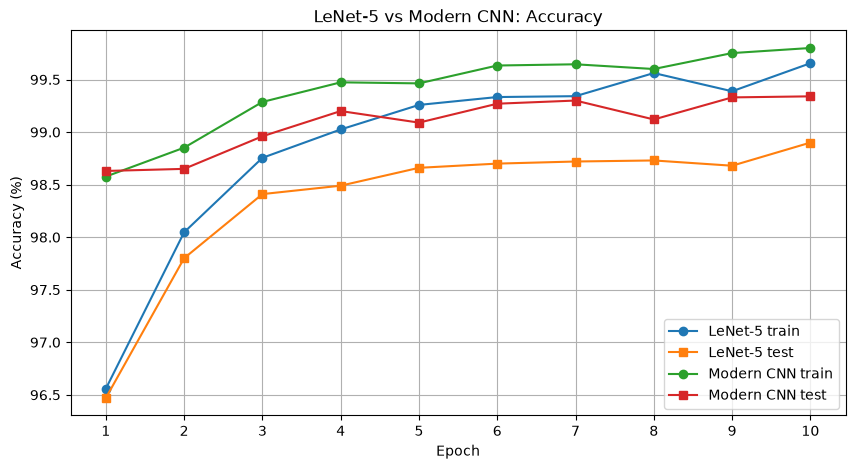

In [ ]:
epoch_numbers = range(1, epochs_mnist + 1)

plt.figure(figsize=(10, 5))
for name, history in (("LeNet-5", history_lenet), ("Modern CNN", history_cnn)):
    plt.plot(epoch_numbers, history["train_acc"], marker="o", label=f"{name} train")
    plt.plot(epoch_numbers, history["test_acc"], marker="s", label=f"{name} test")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("LeNet-5 vs Modern CNN: Accuracy")
plt.xticks(list(epoch_numbers))
plt.grid(True)
plt.legend()
plt.show()

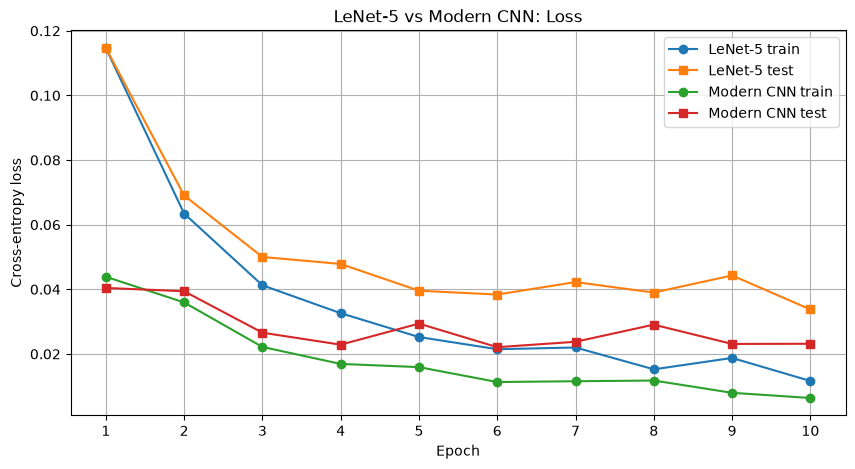

In [ ]:
plt.figure(figsize=(10, 5))
for name, history in (("LeNet-5", history_lenet), ("Modern CNN", history_cnn)):
    plt.plot(epoch_numbers, history["train_loss"], marker="o", label=f"{name} train")
    plt.plot(epoch_numbers, history["test_loss"], marker="s", label=f"{name} test")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("LeNet-5 vs Modern CNN: Loss")
plt.xticks(list(epoch_numbers))
plt.grid(True)
plt.legend()
plt.show()

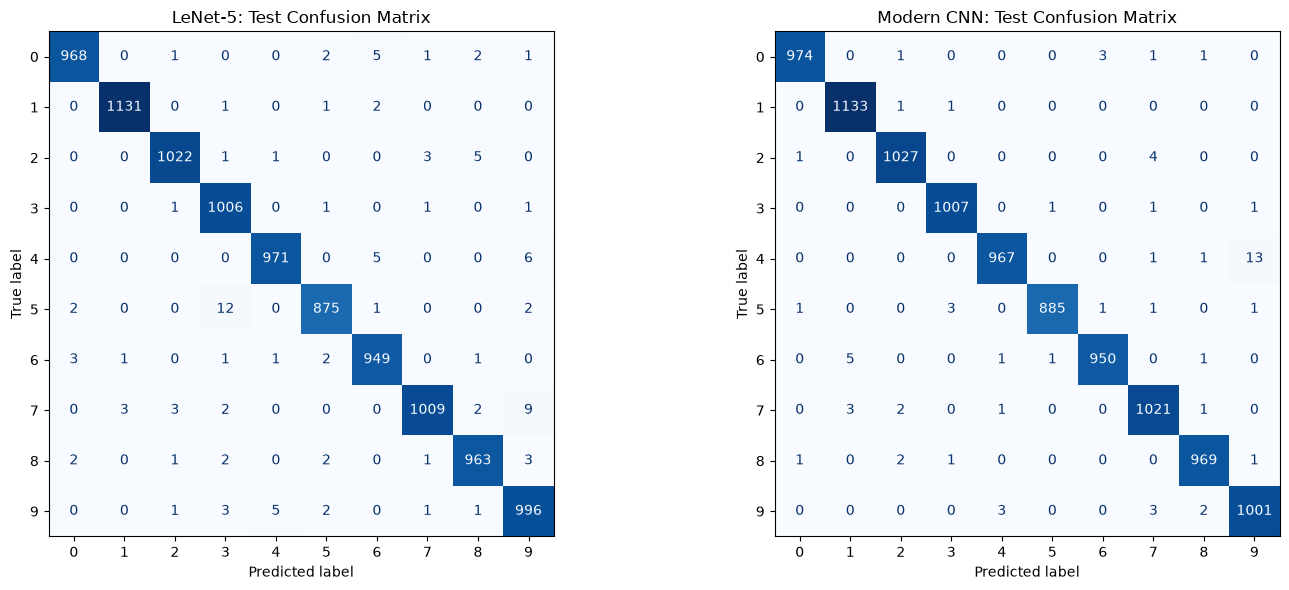

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def get_predictions(model, loader):
    model.eval()
    all_labels = []
    all_predictions = []
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1)
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
    return np.array(all_labels), np.array(all_predictions)


y_true_lenet, y_pred_lenet = get_predictions(model_lenet, testloader_mnist)
y_true_cnn, y_pred_cnn = get_predictions(model_cnn, testloader_mnist)

cm_lenet = confusion_matrix(y_true_lenet, y_pred_lenet, labels=range(10))
cm_cnn = confusion_matrix(y_true_cnn, y_pred_cnn, labels=range(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cm, title in zip(
    axes,
    (cm_lenet, cm_cnn),
    ("LeNet-5", "Modern CNN")
):
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False
    )
    ax.set_title(f"{title}: Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [ ]:
results_mnist = pd.DataFrame({
    "Model": ["LeNet-5", "Modern CNN"],
    "Train Accuracy (%)": [history_lenet["train_acc"][-1], history_cnn["train_acc"][-1]],
    "Test Accuracy (%)": [history_lenet["test_acc"][-1], history_cnn["test_acc"][-1]],
    "Train Loss": [history_lenet["train_loss"][-1], history_cnn["train_loss"][-1]],
    "Test Loss": [history_lenet["test_loss"][-1], history_cnn["test_loss"][-1]]
})
display(results_mnist.round(4))


def show_top_errors(cm, model_name, n=5):
    errors = cm.copy()
    np.fill_diagonal(errors, 0)
    print(f"\n{model_name}: most frequent classification errors")
    for _ in range(n):
        true_digit, predicted_digit = np.unravel_index(errors.argmax(), errors.shape)
        count = errors[true_digit, predicted_digit]
        if count == 0:
            break
        print(f"Actual {true_digit} → Predicted {predicted_digit}: {count}")
        errors[true_digit, predicted_digit] = 0


show_top_errors(cm_lenet, "LeNet-5")
show_top_errors(cm_cnn, "Modern CNN")

,Model,Train Accuracy (%),Test Accuracy (%),Train Loss,Test Loss
0,LeNet-5,99.655,98.90,0.0116,0.0338
1,Modern CNN,99.800,99.34,0.0064,0.0232



LeNet-5: most frequent classification errors
Actual 5 → Predicted 3: 12
Actual 7 → Predicted 9: 9
Actual 4 → Predicted 9: 6
Actual 0 → Predicted 6: 5
Actual 2 → Predicted 8: 5

Modern CNN: most frequent classification errors
Actual 4 → Predicted 9: 13
Actual 6 → Predicted 1: 5
Actual 2 → Predicted 7: 4
Actual 0 → Predicted 6: 3
Actual 5 → Predicted 3: 3


## Question 3

In [ ]:
import copy
import time
import zipfile
import urllib.request
from pathlib import Path
from torch.optim import lr_scheduler
from torchvision import datasets, models
from torchvision.models import ResNet18_Weights

# Download to /content on Colab, or the current folder elsewhere
work_dir = Path("/content") if Path("/content").is_dir() else Path.cwd()
zip_path = work_dir / "hymenoptera_data.zip"
data_dir = work_dir / "data" / "hymenoptera_data"

if not data_dir.is_dir():
    if not zip_path.exists():
        url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
        urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(work_dir / "data")

print("Dataset directory:", data_dir)
print("Splits:", sorted(p.name for p in data_dir.iterdir() if p.is_dir()))

Dataset directory: d:\Semester 5\Image Processing\Assignment 3\data\hymenoptera_data
Splits: ['train', 'val']


In [ ]:
data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406],
                             [0.229, 0.224, 0.225])
    ])
}

image_datasets = {
    phase: datasets.ImageFolder(str(data_dir / phase), transform=data_transforms[phase])
    for phase in ("train", "val")
}

dataloaders = {
    phase: torch.utils.data.DataLoader(
        image_datasets[phase],
        batch_size=4,
        shuffle=(phase == "train"),
        num_workers=2
    )
    for phase in ("train", "val")
}

dataset_sizes = {phase: len(image_datasets[phase]) for phase in ("train", "val")}
class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Training images:", dataset_sizes["train"])
print("Validation images:", dataset_sizes["val"])

Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


### 3(a)

In [ ]:
model_ft = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion_ft = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
scheduler_ft = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)
num_epochs_resnet = 25

print("Output layer:", model_ft.fc)
print("Trainable parameters:", sum(p.numel() for p in model_ft.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\User/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Output layer: Linear(in_features=512, out_features=2, bias=True)
Trainable parameters: 11177538


In [ ]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = -1.0
    best_epoch = 0
    start_time = time.time()

    for epoch in range(num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        for phase in ("train", "val"):
            if phase == "train":
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)
                optimizer.zero_grad(set_to_none=True)

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    preds = outputs.argmax(dim=1)
                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += (preds == labels).sum().item()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = 100 * running_corrects / dataset_sizes[phase]
            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)
            print(f"{phase}: Loss = {epoch_loss:.4f}, Accuracy = {epoch_acc:.2f}%")

            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_epoch = epoch + 1
                best_model_wts = copy.deepcopy(model.state_dict())

        scheduler.step()

    print(f"\nTraining duration: {time.time() - start_time:.1f} seconds")
    print(f"Best validation accuracy: {best_acc:.2f}% (epoch {best_epoch})")
    model.load_state_dict(best_model_wts)
    return model, history, best_epoch

In [ ]:
model_ft, history_ft, best_epoch_ft = train_model(
    model_ft, criterion_ft, optimizer_ft, scheduler_ft,
    num_epochs=num_epochs_resnet
)


Epoch 1/25
train: Loss = 0.5367, Accuracy = 73.77%
val: Loss = 0.2100, Accuracy = 92.81%

Epoch 2/25
train: Loss = 0.5057, Accuracy = 77.87%
val: Loss = 0.2269, Accuracy = 93.46%

Epoch 3/25
train: Loss = 0.5652, Accuracy = 79.10%
val: Loss = 0.2371, Accuracy = 92.81%

Epoch 4/25
train: Loss = 0.6589, Accuracy = 77.87%
val: Loss = 0.2273, Accuracy = 88.89%

Epoch 5/25
train: Loss = 0.3575, Accuracy = 86.89%
val: Loss = 0.3205, Accuracy = 91.50%

Epoch 6/25
train: Loss = 0.5074, Accuracy = 79.10%
val: Loss = 0.5341, Accuracy = 83.66%

Epoch 7/25
train: Loss = 0.5463, Accuracy = 84.43%
val: Loss = 0.2454, Accuracy = 89.54%

Epoch 8/25
train: Loss = 0.2955, Accuracy = 85.66%
val: Loss = 0.2207, Accuracy = 92.81%

Epoch 9/25
train: Loss = 0.3764, Accuracy = 81.97%
val: Loss = 0.2166, Accuracy = 91.50%

Epoch 10/25
train: Loss = 0.4187, Accuracy = 82.38%
val: Loss = 0.2317, Accuracy = 92.16%

Epoch 11/25
train: Loss = 0.2570, Accuracy = 88.52%
val: Loss = 0.2177, Accuracy = 92.81%

Epoch 1

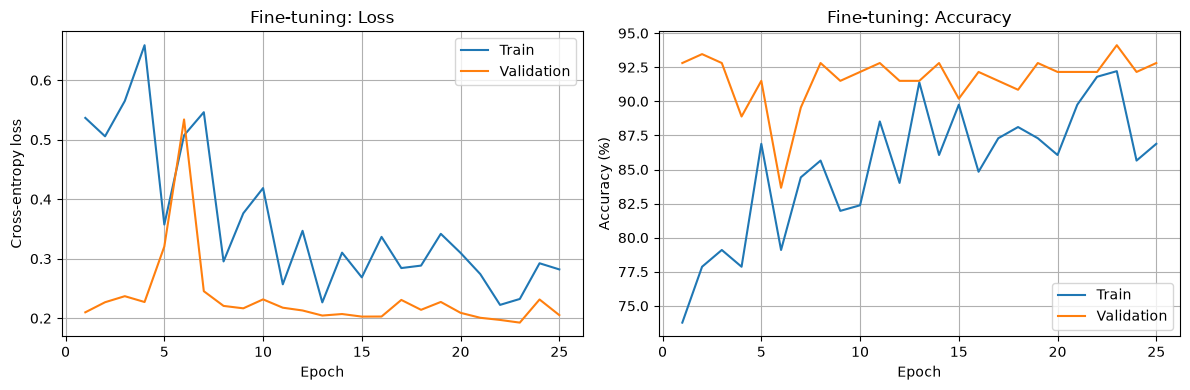

Final epoch train accuracy: 86.89%
Final epoch val accuracy:   92.81%
Best validation accuracy:  94.12%
Best epoch: 23


In [ ]:
resnet_epochs = range(1, num_epochs_resnet + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(resnet_epochs, history_ft["train_loss"], label="Train")
axes[0].plot(resnet_epochs, history_ft["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Fine-tuning: Loss")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(resnet_epochs, history_ft["train_acc"], label="Train")
axes[1].plot(resnet_epochs, history_ft["val_acc"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Fine-tuning: Accuracy")
axes[1].grid(True)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Final epoch train accuracy: {history_ft['train_acc'][-1]:.2f}%")
print(f"Final epoch val accuracy:   {history_ft['val_acc'][-1]:.2f}%")
print(f"Best validation accuracy:  {max(history_ft['val_acc']):.2f}%")
print(f"Best epoch: {best_epoch_ft}")

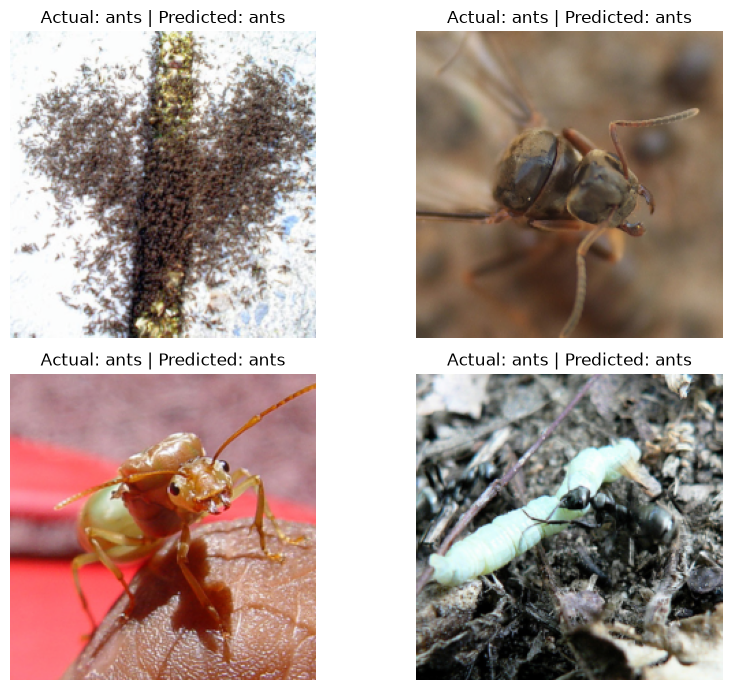

In [ ]:
model_ft.eval()
images, labels = next(iter(dataloaders["val"]))

with torch.no_grad():
    outputs = model_ft(images.to(device))
    predictions = outputs.argmax(dim=1).cpu()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()
    image = np.clip(image * std + mean, 0, 1)
    ax.imshow(image)
    ax.set_title(f"Actual: {class_names[labels[i].item()]} | "
                 f"Predicted: {class_names[predictions[i].item()]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
torch.save(model_ft.state_dict(), work_dir / "resnet18_finetuned_hymenoptera.pth")

### 3(b)

In [ ]:
class FixedFeatureResNet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = models.resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
        for param in self.backbone.parameters():
            param.requires_grad = False
        self.backbone.fc = nn.Linear(self.backbone.fc.in_features, 2)

    def forward(self, x):
        return self.backbone(x)

    def train(self, mode=True):
        super().train(mode)
        if mode:
            # Freeze BatchNorm running statistics in the pretrained backbone
            self.backbone.eval()
            self.backbone.fc.train()
        return self


model_feat = FixedFeatureResNet18().to(device)

total_params = sum(p.numel() for p in model_feat.parameters())
trainable_params = sum(p.numel() for p in model_feat.parameters() if p.requires_grad)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Frozen parameters:", total_params - trainable_params)

Total parameters: 11177538
Trainable parameters: 1026
Frozen parameters: 11176512


In [ ]:
criterion_feat = nn.CrossEntropyLoss()
optimizer_feat = optim.SGD(
    model_feat.backbone.fc.parameters(), lr=0.001, momentum=0.9
)
scheduler_feat = lr_scheduler.StepLR(optimizer_feat, step_size=7, gamma=0.1)

model_feat, history_feat, best_epoch_feat = train_model(
    model_feat, criterion_feat, optimizer_feat, scheduler_feat,
    num_epochs=num_epochs_resnet
)


Epoch 1/25
train: Loss = 0.3247, Accuracy = 82.79%
val: Loss = 0.1318, Accuracy = 96.73%

Epoch 2/25
train: Loss = 0.1837, Accuracy = 90.16%
val: Loss = 0.1420, Accuracy = 96.73%

Epoch 3/25
train: Loss = 0.1517, Accuracy = 93.44%
val: Loss = 0.1401, Accuracy = 96.08%

Epoch 4/25
train: Loss = 0.1025, Accuracy = 96.31%
val: Loss = 0.1654, Accuracy = 94.77%

Epoch 5/25
train: Loss = 0.1217, Accuracy = 94.67%
val: Loss = 0.1365, Accuracy = 95.42%

Epoch 6/25
train: Loss = 0.1201, Accuracy = 96.72%
val: Loss = 0.1670, Accuracy = 94.12%

Epoch 7/25
train: Loss = 0.0749, Accuracy = 96.72%
val: Loss = 0.1588, Accuracy = 95.42%

Epoch 8/25
train: Loss = 0.0732, Accuracy = 98.36%
val: Loss = 0.1610, Accuracy = 95.42%

Epoch 9/25
train: Loss = 0.0711, Accuracy = 96.72%
val: Loss = 0.1571, Accuracy = 95.42%

Epoch 10/25
train: Loss = 0.0708, Accuracy = 97.13%
val: Loss = 0.1580, Accuracy = 95.42%

Epoch 11/25
train: Loss = 0.0640, Accuracy = 97.95%
val: Loss = 0.1585, Accuracy = 95.42%

Epoch 1

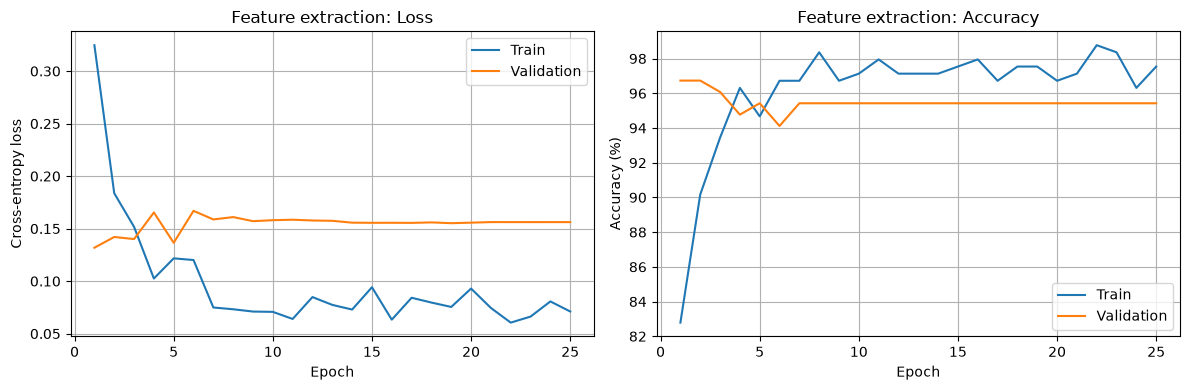

Final epoch train accuracy: 97.54%
Final epoch val accuracy:   95.42%
Best validation accuracy:  96.73%
Best epoch: 1


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(resnet_epochs, history_feat["train_loss"], label="Train")
axes[0].plot(resnet_epochs, history_feat["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Feature extraction: Loss")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(resnet_epochs, history_feat["train_acc"], label="Train")
axes[1].plot(resnet_epochs, history_feat["val_acc"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Feature extraction: Accuracy")
axes[1].grid(True)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Final epoch train accuracy: {history_feat['train_acc'][-1]:.2f}%")
print(f"Final epoch val accuracy:   {history_feat['val_acc'][-1]:.2f}%")
print(f"Best validation accuracy:  {max(history_feat['val_acc']):.2f}%")
print(f"Best epoch: {best_epoch_feat}")

### Comparison

In [ ]:
comparison = pd.DataFrame({
    "Approach": ["Fine-tuning", "Feature extraction"],
    "Final Train Accuracy (%)": [history_ft["train_acc"][-1], history_feat["train_acc"][-1]],
    "Final Val Accuracy (%)": [history_ft["val_acc"][-1], history_feat["val_acc"][-1]],
    "Best Val Accuracy (%)": [max(history_ft["val_acc"]), max(history_feat["val_acc"])],
    "Best Epoch": [best_epoch_ft, best_epoch_feat]
})
display(comparison.round(2))

,Approach,Final Train Accuracy (%),Final Val Accuracy (%),Best Val Accuracy (%),Best Epoch
0,Fine-tuning,86.89,92.81,94.12,23
1,Feature extraction,97.54,95.42,96.73,1


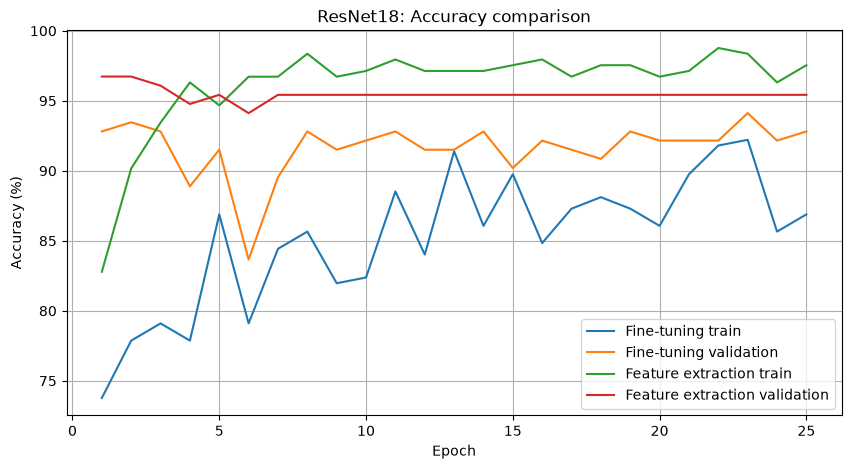

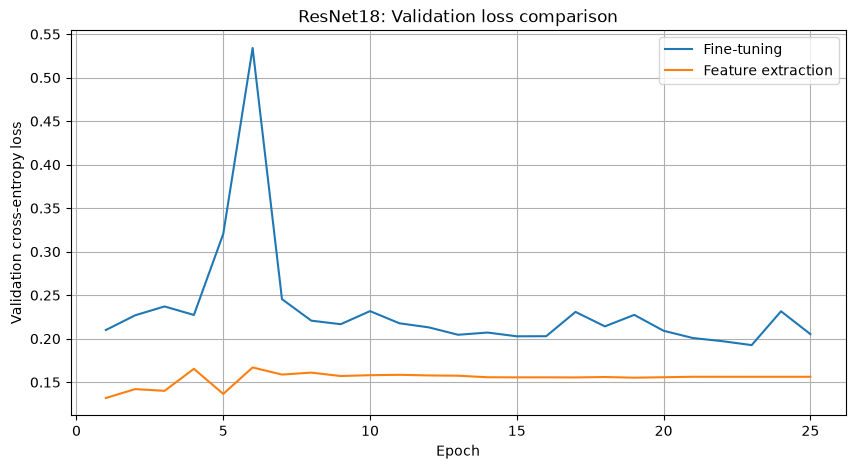

In [ ]:
plt.figure(figsize=(10, 5))
for name, history in (("Fine-tuning", history_ft), ("Feature extraction", history_feat)):
    plt.plot(resnet_epochs, history["train_acc"], label=f"{name} train")
    plt.plot(resnet_epochs, history["val_acc"], label=f"{name} validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet18: Accuracy comparison")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(resnet_epochs, history_ft["val_loss"], label="Fine-tuning")
plt.plot(resnet_epochs, history_feat["val_loss"], label="Feature extraction")
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy loss")
plt.title("ResNet18: Validation loss comparison")
plt.grid(True)
plt.legend()
plt.show()

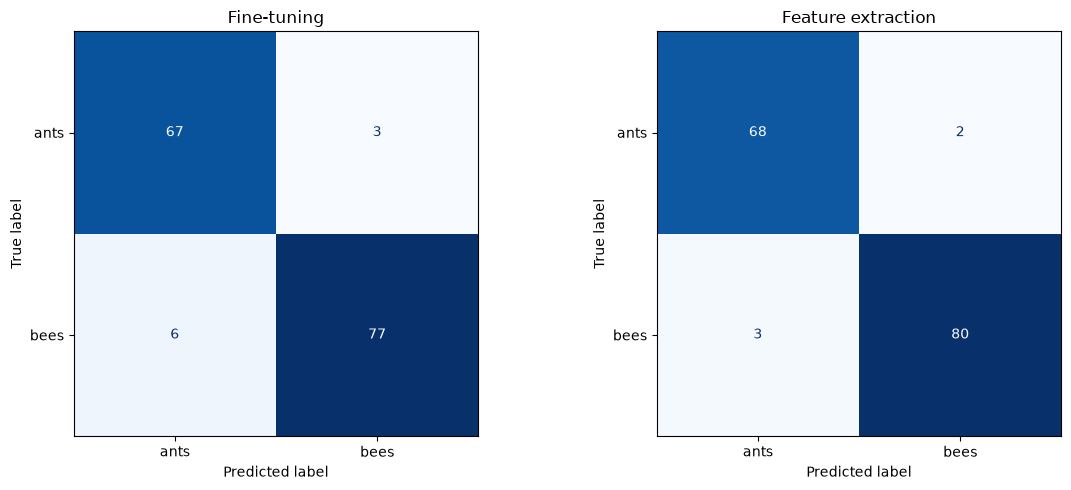

In [ ]:
y_true_ft, y_pred_ft = get_predictions(model_ft, dataloaders["val"])
y_true_feat, y_pred_feat = get_predictions(model_feat, dataloaders["val"])

cm_ft = confusion_matrix(y_true_ft, y_pred_ft, labels=[0, 1])
cm_feat = confusion_matrix(y_true_feat, y_pred_feat, labels=[0, 1])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cm, title in zip(axes, (cm_ft, cm_feat), ("Fine-tuning", "Feature extraction")):
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [ ]:
torch.save(model_feat.state_dict(), work_dir / "resnet18_feature_extractor.pth")
comparison.to_csv(work_dir / "resnet18_comparison.csv", index=False)
results_mnist.to_csv(work_dir / "mnist_comparison.csv", index=False)

print("Saved model checkpoints and comparison tables to:", work_dir)

Saved model checkpoints and comparison tables to: d:\Semester 5\Image Processing\Assignment 3
